# Reálné parametry


In [1]:
import math
import struct
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

def sphere(x):
    return sum(xi ** 2 for xi in x)

def rosenbrock(x):
    return sum(100.0 * (x[i + 1] - x[i] ** 2) ** 2 + (x[i] - 1.0) ** 2 for i in range(len(x) - 1))

def schwefel(x):
    return 418.9829 * len(x) - sum(xi * math.sin(math.sqrt(abs(xi))) for xi in x)

BITS = 32

def bits_to_int(bits):
    value = 0
    for bit in bits:
        value = (value << 1) | bit
    return value

def decode_ieee754(bits, lb, ub):
    value = struct.unpack(">f", bits_to_int(bits).to_bytes(4, "big"))[0]
    if math.isnan(value):
        return (lb + ub) / 2.0
    return max(lb, min(ub, value))

def decode_fixed_point(bits, lb, ub):
    int_bits = math.ceil(math.log2(max(abs(lb), abs(ub)) + 1))
    frac_bits = BITS - 1 - int_bits
    raw = bits_to_int(bits)
    if raw & (1 << (BITS - 1)):
        raw -= 1 << BITS
    return max(lb, min(ub, raw / 2 ** frac_bits))

def decode_bcd(bits, lb, ub):
    int_digits = len(str(int(max(abs(lb), abs(ub)))))
    frac_digits = 7 - int_digits
    digits = [bits_to_int(bits[i:i + 4]) for i in range(0, BITS, 4)]
    sign = -1.0 if digits[0] >= 8 else 1.0
    number = 0
    for digit in digits[1:]:
        number = number * 10 + digit % 10
    return max(lb, min(ub, sign * number / 10 ** frac_digits))

def decode_binary(individual, decoder, lb, ub):
    return [decoder(individual[i:i + BITS], lb, ub) for i in range(0, len(individual), BITS)]

def selection_rank(population, costs):
    n = len(population)
    indexed = sorted(range(n), key=lambda i: costs[i], reverse=True)
    total_rank = n * (n + 1) // 2
    pick = random.uniform(0, total_rank)
    current = 0
    for rank, idx in enumerate(indexed, start=1):
        current += rank
        if current >= pick:
            return list(population[idx])
    return list(population[indexed[-1]])

def crossover_one_point(parent1, parent2):
    length = len(parent1)
    if length <= 1:
        return list(parent1), list(parent2)
    point = random.randint(1, length - 1)
    child1 = parent1[:point] + parent2[point:]
    child2 = parent2[:point] + parent1[point:]
    return child1, child2

def mutate_binary(individual, mutation_rate):
    return [1 - bit if random.random() < mutation_rate else bit for bit in individual]

def mutate_gaussian(individual, mutation_rate, sigma, lb, ub):
    return [min(ub, max(lb, x + random.gauss(0, sigma))) if random.random() < mutation_rate else x
            for x in individual]

def mutate_uniform(individual, mutation_rate, lb, ub):
    return [random.uniform(lb, ub) if random.random() < mutation_rate else x for x in individual]
    

In [2]:
def run_genetic_algorithm(cost_fn, dim, lb, ub, representation, max_evals=10000, pop_size=50,
                          elite_ratio=0.1, mutation_rate=0.01, crossover_rate=0.9, sigma=None):
    if representation in ("ieee754", "fixed", "bcd"):
        decoder = {"ieee754": decode_ieee754, "fixed": decode_fixed_point, "bcd": decode_bcd}[representation]
        evaluate = lambda ind: cost_fn(decode_binary(ind, decoder, lb, ub))
        create = lambda: [random.randint(0, 1) for _ in range(dim * BITS)]
        mutate = lambda ind: mutate_binary(ind, mutation_rate)
        crossover = lambda a, b: crossover_one_point(a, b)
    else:
        evaluate = cost_fn
        create = lambda: [random.uniform(lb, ub) for _ in range(dim)]
        if representation == "real_normal":
            mutate = lambda ind: mutate_gaussian(ind, mutation_rate, sigma, lb, ub)
        else:
            mutate = lambda ind: mutate_uniform(ind, mutation_rate, lb, ub)
        crossover = lambda a, b: crossover_one_point(a, b)

    population = [create() for _ in range(pop_size)]
    costs = [evaluate(ind) for ind in population]
    eval_count = pop_size

    elite_count = max(1, int(pop_size * elite_ratio))

    best_so_far = min(costs)
    convergence = [best_so_far] * eval_count

    while eval_count < max_evals:
        sorted_indices = sorted(range(pop_size), key=lambda i: costs[i])
        new_population = [list(population[i]) for i in sorted_indices[:elite_count]]
        new_costs = [costs[i] for i in sorted_indices[:elite_count]]

        while len(new_population) < pop_size:
            p1 = selection_rank(population, costs)
            p2 = selection_rank(population, costs)

            if random.random() < crossover_rate:
                c1, c2 = crossover(p1, p2)
            else:
                c1, c2 = list(p1), list(p2)

            c1 = mutate(c1)
            c2 = mutate(c2)

            new_population.append(c1)
            if len(new_population) < pop_size:
                new_population.append(c2)

        population = new_population
        remaining = max_evals - eval_count
        offspring_to_eval = min(pop_size - elite_count, remaining)

        for i in range(elite_count, elite_count + offspring_to_eval):
            cost = evaluate(population[i])
            new_costs.append(cost)
            eval_count += 1
            if cost < best_so_far:
                best_so_far = cost
            convergence.append(best_so_far)

        if offspring_to_eval < (pop_size - elite_count):
            break

        costs = new_costs

    if len(convergence) < max_evals:
        convergence.extend([best_so_far] * (max_evals - len(convergence)))
    else:
        convergence = convergence[:max_evals]

    return convergence, best_so_far

## Vliv parametrů mutace v reálném GA


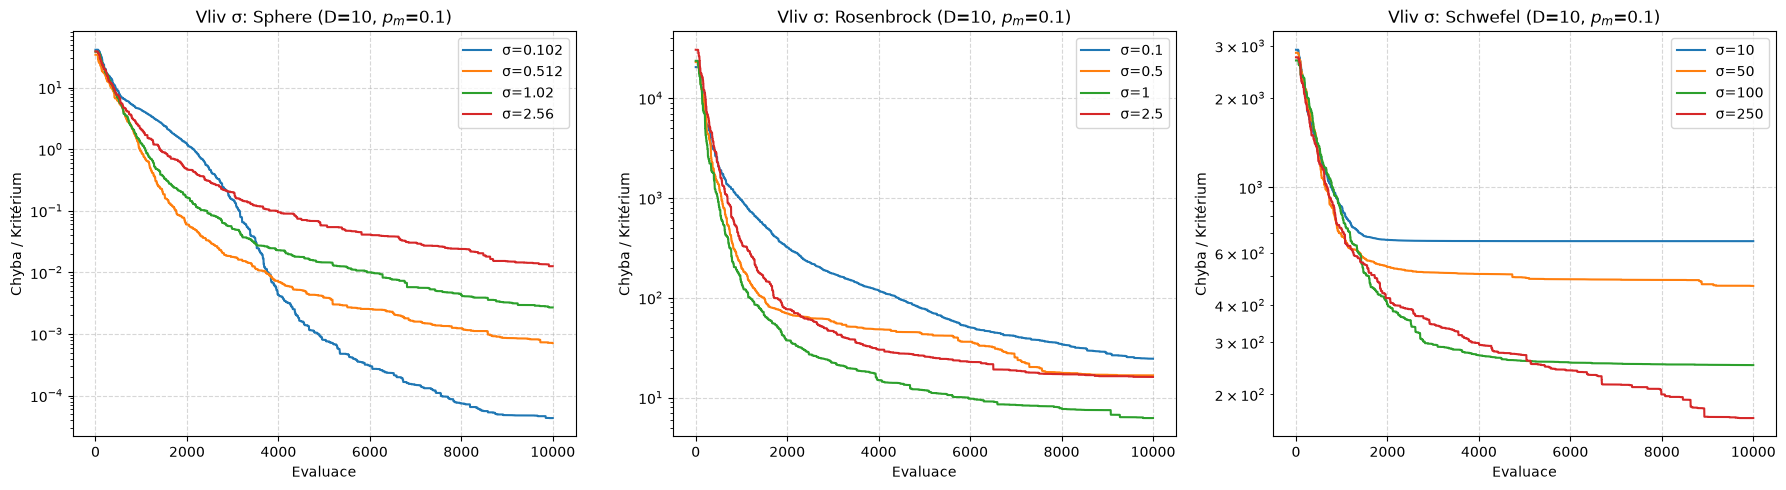

,Funkce,Nastavení,Nejlepší,Nejhorší,Průměr,Medián,Směr. odchylka
0,Sphere,σ=0.102,0.000008,0.000089,0.000043,0.000044,0.000025
1,Sphere,σ=0.512,0.000335,0.001620,0.000714,0.000691,0.000355
2,Sphere,σ=1.02,0.000518,0.005028,0.002698,0.002535,0.001244
3,Sphere,σ=2.56,0.002894,0.026044,0.012605,0.010462,0.006853
4,Rosenbrock,σ=0.1,2.790931,104.130514,24.500882,7.681077,35.588291
5,Rosenbrock,σ=0.5,4.381431,108.053224,16.683811,7.019011,30.488965
6,Rosenbrock,σ=1,0.724408,9.035790,6.228063,6.830076,2.473506
7,Rosenbrock,σ=2.5,4.166845,68.624839,16.089875,9.407426,18.157599
8,Schwefel,σ=10,118.450966,1164.777712,657.544158,641.584927,300.729580
9,Schwefel,σ=50,237.137897,1026.862516,464.458754,405.256921,233.253793


In [3]:
dim = 10
max_evals = 10000
num_runs = 10
problems = {
    "Sphere": (sphere, -5.12, 5.12),
    "Rosenbrock": (rosenbrock, -5.0, 5.0),
    "Schwefel": (schwefel, -500.0, 500.0)
}

sigma_variants = [0.01, 0.05, 0.10, 0.25]
fixed_pm = 0.1
fig, axes = plt.subplots(1, len(problems), figsize=(18, 5))
best_sigma_results = {}
sigma_stats_records = []

for p_idx, (p_name, (p_fn, lb, ub)) in enumerate(problems.items()):
    ax = axes[p_idx]
    best_mean = float("inf")
    best_cfg = None

    for sigma_ratio in sigma_variants:
        sigma = sigma_ratio * (ub - lb)
        runs_convergence = []
        runs_scores = []
        for _ in range(num_runs):
            conv, best_val = run_genetic_algorithm(
                cost_fn=p_fn, dim=dim, lb=lb, ub=ub, representation="real_normal",
                max_evals=max_evals, pop_size=50, elite_ratio=0.1,
                mutation_rate=fixed_pm, crossover_rate=0.9, sigma=sigma
            )
            runs_convergence.append(conv)
            runs_scores.append(best_val)

        mean_conv = np.mean(runs_convergence, axis=0)
        ax.plot(mean_conv, label=f"σ={sigma:.3g}")

        m_score = np.mean(runs_scores)
        if m_score < best_mean:
            best_mean = m_score
            best_cfg = sigma

        sigma_stats_records.append({
            "Funkce": p_name,
            "Nastavení": f"σ={sigma:.3g}",
            "Nejlepší": np.min(runs_scores),
            "Nejhorší": np.max(runs_scores),
            "Průměr": np.mean(runs_scores),
            "Medián": np.median(runs_scores),
            "Směr. odchylka": np.std(runs_scores)
        })

    best_sigma_results[p_name] = (best_cfg, best_mean)
    ax.set_title(f"Vliv σ: {p_name} (D={dim}, $p_m$={fixed_pm})")
    ax.set_xlabel("Evaluace")
    ax.set_ylabel("Chyba / Kritérium")
    ax.set_yscale("log")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

df_sigma_stats = pd.DataFrame(sigma_stats_records)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(df_sigma_stats)


## Vliv pravděpodobnosti mutace v reálném GA


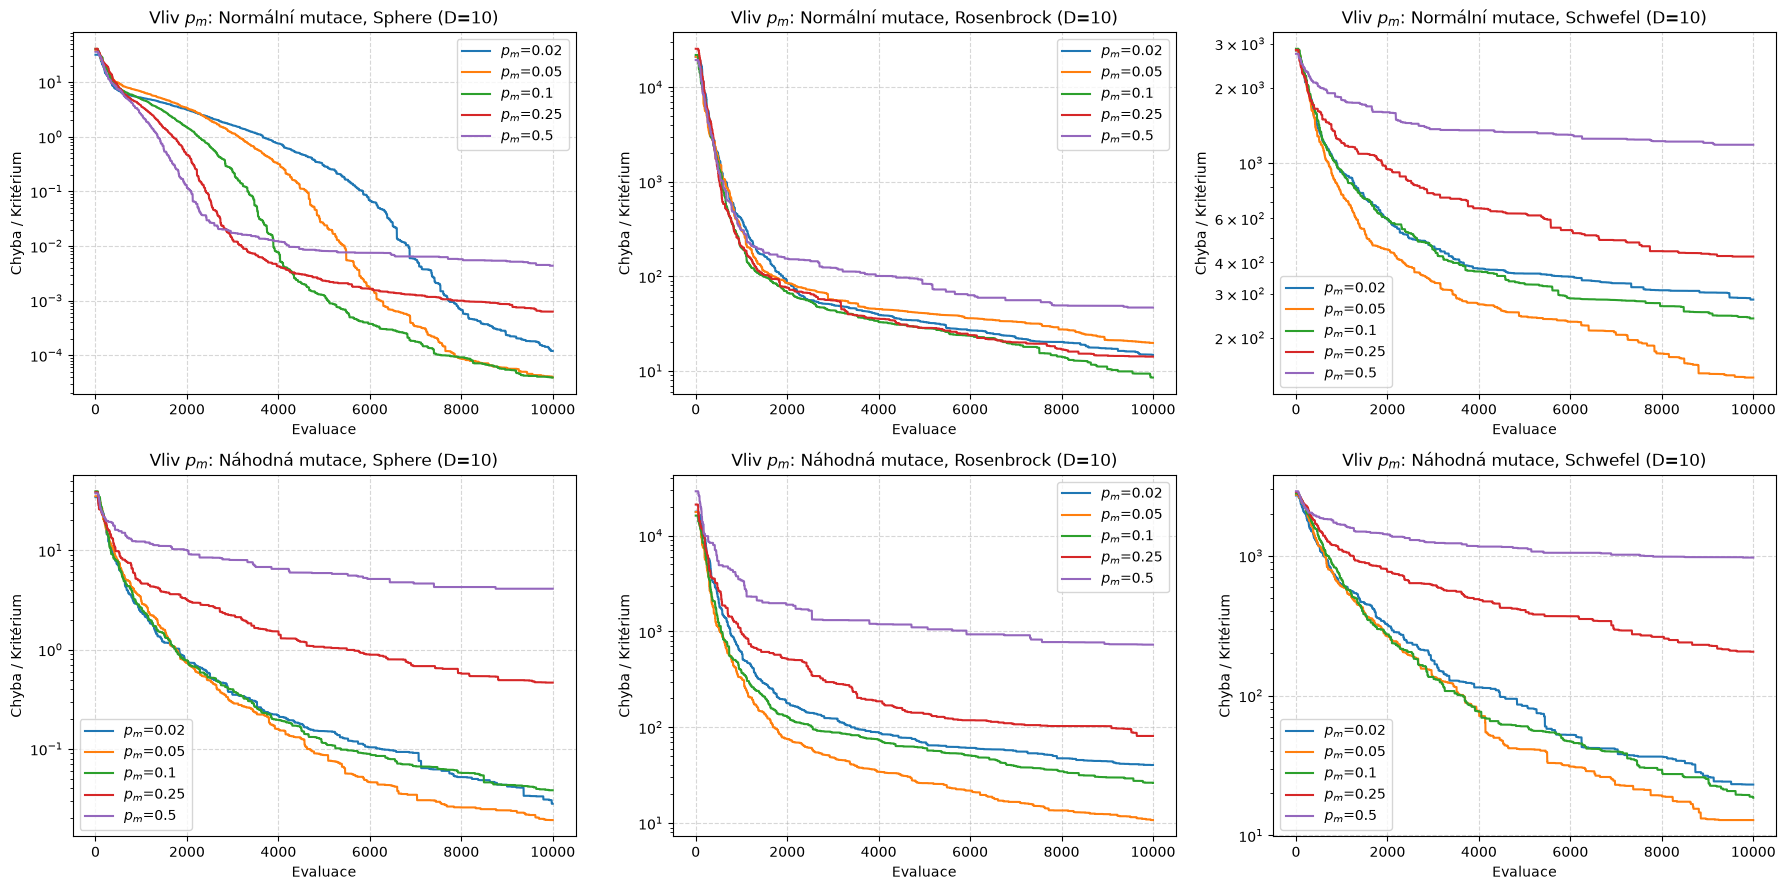

,Funkce,Mutace,Nastavení,Nejlepší,Nejhorší,Průměr,Medián,Směr. odchylka
0,Sphere,Normální mutace,pm=0.02,0.000023,0.000245,0.000120,0.000127,0.000075
1,Sphere,Normální mutace,pm=0.05,0.000017,0.000074,0.000039,0.000034,0.000019
2,Sphere,Normální mutace,pm=0.1,0.000009,0.000102,0.000039,0.000037,0.000027
3,Sphere,Normální mutace,pm=0.25,0.000359,0.001030,0.000629,0.000550,0.000214
4,Sphere,Normální mutace,pm=0.5,0.000741,0.007996,0.004354,0.003876,0.001990
5,Rosenbrock,Normální mutace,pm=0.02,0.711327,79.469560,14.769460,7.952313,21.899965
6,Rosenbrock,Normální mutace,pm=0.05,5.713269,85.323400,19.761869,10.085642,23.790181
7,Rosenbrock,Normální mutace,pm=0.1,2.580539,18.019291,8.498140,7.218291,4.621340
8,Rosenbrock,Normální mutace,pm=0.25,7.996345,25.342027,14.148229,11.983131,5.039335
9,Rosenbrock,Normální mutace,pm=0.5,29.930711,63.374664,46.739823,45.143011,13.023064


In [4]:
mutation_variants = [0.02, 0.05, 0.10, 0.25, 0.50]
mutation_types = {"Normální mutace": "real_normal", "Náhodná mutace": "real_uniform"}
fig, axes = plt.subplots(len(mutation_types), len(problems), figsize=(18, 9))
best_mut_results = {}
mut_stats_records = []

for m_idx, (m_name, m_type) in enumerate(mutation_types.items()):
    for p_idx, (p_name, (p_fn, lb, ub)) in enumerate(problems.items()):
        ax = axes[m_idx, p_idx]
        best_mean = float("inf")
        best_cfg = None
        sigma = best_sigma_results[p_name][0]

        for mut_rate in mutation_variants:
            runs_convergence = []
            runs_scores = []
            for _ in range(num_runs):
                conv, best_val = run_genetic_algorithm(
                    cost_fn=p_fn, dim=dim, lb=lb, ub=ub, representation=m_type,
                    max_evals=max_evals, pop_size=50, elite_ratio=0.1,
                    mutation_rate=mut_rate, crossover_rate=0.9, sigma=sigma
                )
                runs_convergence.append(conv)
                runs_scores.append(best_val)

            mean_conv = np.mean(runs_convergence, axis=0)
            ax.plot(mean_conv, label=f"$p_m$={mut_rate}")

            m_score = np.mean(runs_scores)
            if m_score < best_mean:
                best_mean = m_score
                best_cfg = mut_rate

            mut_stats_records.append({
                "Funkce": p_name,
                "Mutace": m_name,
                "Nastavení": f"pm={mut_rate}",
                "Nejlepší": np.min(runs_scores),
                "Nejhorší": np.max(runs_scores),
                "Průměr": np.mean(runs_scores),
                "Medián": np.median(runs_scores),
                "Směr. odchylka": np.std(runs_scores)
            })

        best_mut_results[(m_type, p_name)] = (best_cfg, best_mean)
        ax.set_title(f"Vliv $p_m$: {m_name}, {p_name} (D={dim})")
        ax.set_xlabel("Evaluace")
        ax.set_ylabel("Chyba / Kritérium")
        ax.set_yscale("log")
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend()

plt.tight_layout()
plt.show()

df_mut_stats = pd.DataFrame(mut_stats_records)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(df_mut_stats)


## Porovnání variant reprezentace GA


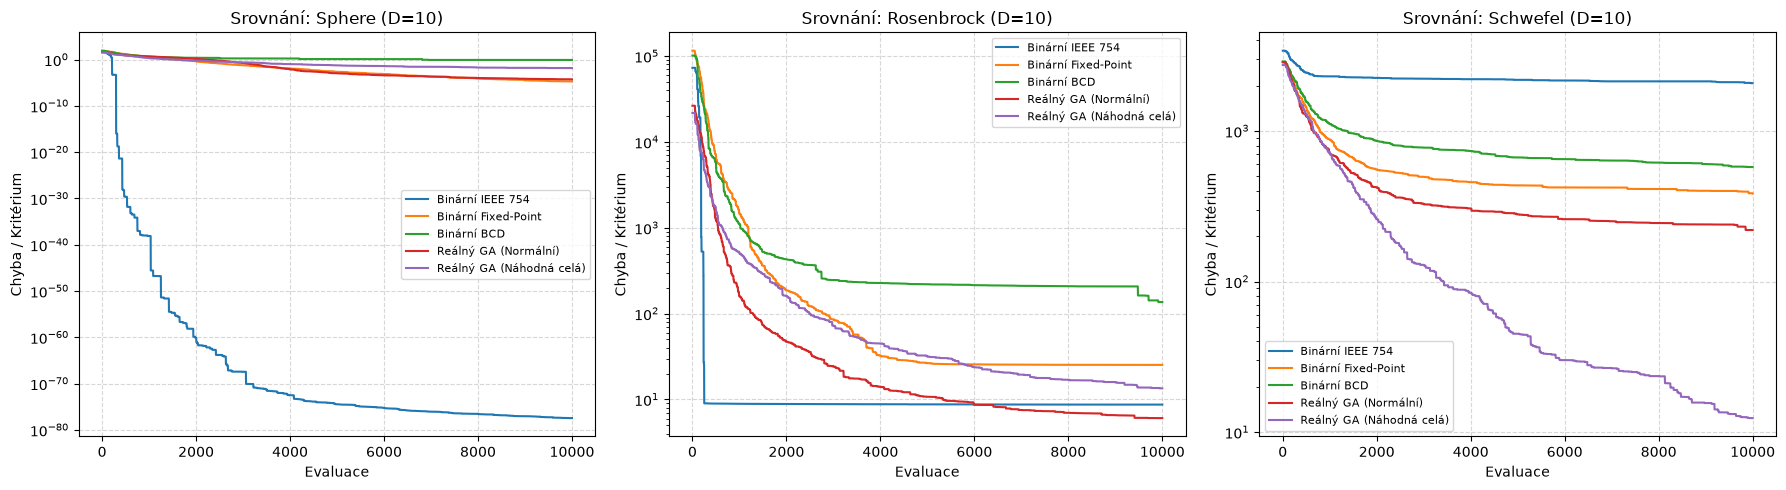

,Funkce,Varianta,Nejlepší,Nejhorší,Průměr,Medián,Směr. odchylka
0,Sphere,Binární IEEE 754,1.985396e-79,1.037324e-77,3.338826e-78,2.413638e-78,2.935235e-78
1,Sphere,Binární Fixed-Point,2.911135e-06,3.963795e-05,1.906661e-05,2.113566e-05,9.741736e-06
2,Sphere,Binární BCD,3.495854e-05,4.001438e+00,8.168863e-01,2.098428e-02,1.592286e+00
3,Sphere,Reálný GA (Normální),9.038426e-06,1.177702e-04,5.302752e-05,5.439864e-05,3.094487e-05
4,Sphere,Reálný GA (Náhodná celá),5.423781e-03,2.892216e-02,1.452869e-02,1.529034e-02,6.241214e-03
5,Rosenbrock,Binární IEEE 754,8.665846e+00,8.751462e+00,8.711986e+00,8.710983e+00,2.444157e-02
6,Rosenbrock,Binární Fixed-Point,8.083415e+00,1.034974e+02,2.527285e+01,8.973004e+00,3.297863e+01
7,Rosenbrock,Binární BCD,7.319637e+00,1.126064e+03,1.363361e+02,1.260452e+01,3.310056e+02
8,Rosenbrock,Reálný GA (Normální),2.612266e+00,8.581282e+00,6.060607e+00,6.327689e+00,2.046659e+00
9,Rosenbrock,Reálný GA (Náhodná celá),2.435083e+00,4.656778e+01,1.348040e+01,9.197600e+00,1.251207e+01


In [5]:
binary_mutation_rate = 0.01
variants = {
    "Binární IEEE 754": "ieee754",
    "Binární Fixed-Point": "fixed",
    "Binární BCD": "bcd",
    "Reálný GA (Normální)": "real_normal",
    "Reálný GA (Náhodná celá)": "real_uniform"
}

fig, axes = plt.subplots(1, len(problems), figsize=(18, 5))
comparison_records = []

for p_idx, (p_name, (p_fn, lb, ub)) in enumerate(problems.items()):
    ax = axes[p_idx]

    for v_name, representation in variants.items():
        if representation == "real_normal":
            params = {"mutation_rate": best_mut_results[(representation, p_name)][0], "sigma": best_sigma_results[p_name][0]}
        elif representation == "real_uniform":
            params = {"mutation_rate": best_mut_results[(representation, p_name)][0]}
        else:
            params = {"mutation_rate": binary_mutation_rate}

        runs_convergence = []
        runs_scores = []
        for _ in range(num_runs):
            conv, best_val = run_genetic_algorithm(
                cost_fn=p_fn, dim=dim, lb=lb, ub=ub, representation=representation,
                max_evals=max_evals, pop_size=50, elite_ratio=0.1, crossover_rate=0.9, **params
            )
            runs_convergence.append(conv)
            runs_scores.append(best_val)

        ax.plot(np.mean(runs_convergence, axis=0), label=v_name)

        comparison_records.append({
            "Funkce": p_name,
            "Varianta": v_name,
            "Nejlepší": np.min(runs_scores),
            "Nejhorší": np.max(runs_scores),
            "Průměr": np.mean(runs_scores),
            "Medián": np.median(runs_scores),
            "Směr. odchylka": np.std(runs_scores)
        })

    ax.set_title(f"Srovnání: {p_name} (D={dim})")
    ax.set_xlabel("Evaluace")
    ax.set_ylabel("Chyba / Kritérium")
    ax.set_yscale("log")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

df_comparison = pd.DataFrame(comparison_records)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(df_comparison)


## Závěr

Na základě provedených experimentů s optimalizací 10D spojitých funkcí (Sphere, Rosenbrock a Schwefel) při rozpočtu 10 000 evaluací a 10 nezávislých bězích lze říci následující:

* **Vliv parametrů normální mutace v reálném GA**
    * **Směrodatná odchylka ($\sigma$, zadaná jako část rozsahu funkce):** Nízká hodnota ($\sigma = 1\ \%$ rozsahu) dala nejlepší výsledek na Sphere ($4{,}3 \cdot 10^{-5}$), na Rosenbrocku však část běhů uvízla (průměr $24{,}5$ proti $6{,}2$ při $\sigma = 10\ \%$). Vysoká odchylka ($\sigma = 25\ \%$) byla nejlepší na Schwefelu ($166$ proti $658$ při $\sigma = 1\ \%$), ale na Sphere dopadla nejhůře ($1{,}3 \cdot 10^{-2}$).
    * **Pravděpodobnost mutace ($p_m$):** U náhodné mutace byla nejlepší $p_m = 0{,}05$ na všech funkcích, u normální mutace $p_m = 0{,}05$ až $0{,}1$ (na Rosenbrocku $0{,}1$). Při $p_m = 0{,}5$ se výsledky výrazně zhoršily u všech funkcí (např. Schwefel kolem $1\,000$), protože je mutována polovina souřadnic a algoritmus se blíží náhodnému prohledávání. Při $p_m = 0{,}02$ byly výsledky horší než při $0{,}05$ na Sphere a Schwefelu.

* **Srovnání kódování do binární reprezentace**
    * **IEEE 754:** Nejlepší výsledek na Sphere ($3 \cdot 10^{-78}$) je dán tím, že rozlišení float32 je nejhustší kolem nuly, která je optimem této funkce. Na Rosenbrocku uvázl v okolí nulového vektoru ($\approx 8{,}7$) a na Schwefelu, kde je nula klamavým atraktorem, je nejhorší ($2\,075$).
    * **Fixed-Point:** Na Sphere dosáhl $1{,}9 \cdot 10^{-5}$ a na Schwefelu byl nejlepší z binárních kódování ($385$). Na Rosenbrocku je průměr $25{,}3$ při mediánu $9{,}0$.
    * **BCD:** Má největší rozptyl výsledků (Sphere průměr $0{,}82$ při mediánu $0{,}021$, Rosenbrock průměr $136$) a na Sphere a Rosenbrocku nejhorší průměr ze všech variant, na Schwefelu je horší než Fixed-Point ($576$ proti $385$).

* **Reálný vs. binární genetický algoritmus**
    * **Reálný GA s normální mutací** dosáhl na Rosenbrocku nejlepšího průměru ($6{,}1$) a na Schwefelu druhého ($220$). Na Sphere ($5{,}3 \cdot 10^{-5}$) ho překonaly IEEE 754 a Fixed-Point, protože konstantní $\sigma$ nedovolí doladit řešení pod velikost kroku.
    * **Reálný GA s náhodnou mutací z celého rozsahu** je horší na Sphere ($1{,}5 \cdot 10^{-2}$) a Rosenbrocku ($13{,}5$), protože nemá lokální doladění, ale na Schwefelu je s odstupem nejlepší ($12{,}4$ proti $220$), protože každá mutace je nezávislým skokem a neuvázne v lokálním minimu.
    * Nejlepší průměr dosáhla na Sphere varianta IEEE 754, na Rosenbrocku reálný GA s normální mutací a na Schwefelu reálný GA s náhodnou mutací, žádná varianta tedy nevyhrála na všech funkcích. Výsledky binárních kódování silně závisí na tom, jak kódování souvisí s tvarem funkce, proto je pro optimalizaci ve spojité doméně spolehlivější reálná reprezentace než překódování do binárního řetězce.
    